# TP4 - Redes convolucionales para clasificar lesiones de piel (ISIC)

**Dataset:** imágenes dermatoscópicas ISIC de 9 clases (~880 imágenes en la carpeta `data/Split_smol`, con una subcarpeta por clase dentro de `train/` y `val/`).

El **código ya está resuelto y probado**. Lo que se evalúa es **su análisis**. El cómputo lleva unos 15-20 minutos (medido en una CPU de 20 núcleos), y les queda la mayor parte de las 2 horas para interpretar resultados.

**Qué se trabaja en este TP:** análisis exploratorio, limpieza de duplicados y split, convoluciones, pooling y campo receptivo, comparación MLP vs. CNN, decisiones de arquitectura, resolución de entrada, data augmentation y evaluación final.
**Qué NO se repite** porque ya lo hicieron en los TP1 a TP3: búsqueda de hiperparámetros con Optuna, dropout/L2/BatchNorm como variables de estudio (la BatchNorm queda fija dentro del bloque convolucional), inicialización y logging con TensorBoard/MLflow.

**Cómo trabajar:** ejecuten de arriba hacia abajo, lean los outputs y completen las celdas **✏️** (observaciones de EDA, explicación del código convolucional y cuatro análisis). Las comparaciones usan **3 semillas** y reportan media ± desvío: una diferencia solo cuenta si supera ese ruido.

**Reglas metodológicas (las mismas de los TPs anteriores):**
- Las entradas van **normalizadas** (media y desvío por canal calculados **solo en train**).
- El **test se usa una sola vez**, en la sección 8. Todo lo demás se decide con validación.
- La augmentation se aplica **solo a train y después del split**.
- Las conclusiones tienen que **coincidir con los outputs** de su corrida.

## Paso previo: ejecución en Google Colab (GPU T4)
Estas celdas se agregaron para correr el notebook en Colab. **Antes de empezar:** *Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU*.

1. **GPU y datos:** verifica la GPU y deja la carpeta del dataset en `data/Split_smol` (que es la ruta que usa `DATA_DIR`). Elegí una fuente en `FUENTE`.
2. **Captura de resultados:** a partir de acá, cada figura que se muestre se guarda sola en `resultados/figuras/` y todo lo que se imprime se copia a `resultados/salida_consola.txt`.

Las librerías que usa el notebook (`torch`, `scikit-learn`, `pandas`, `matplotlib`, `Pillow`) ya vienen instaladas en Colab, así que no hace falta `pip install`.


In [1]:
# ---- Paso previo para Colab: GPU y datos ----
import os, subprocess, shutil
import torch

print("torch", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                                 capture_output=True, text=True).stdout.strip())
else:
    print("AVISO: no hay GPU. Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU, y volver a ejecutar.")

# Fuente del dataset. Elegir UNA:
#   "local"  : la carpeta data/Split_smol ya existe (hay que subirla manualmente a /content/data/Split_smol)
#   "drive"  : tomarla de Google Drive (un .zip o una carpeta; ajustar RUTA_DRIVE)
#   "github" : clonar un repo que contenga la carpeta Split_smol (ajustar REPO_GITHUB)
FUENTE = "github"
RUTA_DRIVE = "/content/drive/MyDrive/Split_smol.zip"
REPO_GITHUB = "https://github.com/cselmo/CNN-en-Skin-Dataset.git"

DATA_DIR_COLAB = "data/Split_smol"        # tiene que coincidir con DATA_DIR de la sección 0

def _buscar_split(raiz):
    # devuelve la carpeta que contiene train/ y val/
    for r, dirs, _ in os.walk(raiz):
        if "train" in dirs and "val" in dirs:
            return r
    return None

if not os.path.isdir(f"{DATA_DIR_COLAB}/train"):
    if FUENTE == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        if RUTA_DRIVE.endswith(".zip"):
            shutil.rmtree("/content/_datos", ignore_errors=True)
            shutil.unpack_archive(RUTA_DRIVE, "/content/_datos")
            origen = "/content/_datos"
        else:
            origen = RUTA_DRIVE
    elif FUENTE == "github":
        shutil.rmtree("/content/_datos", ignore_errors=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_GITHUB, "/content/_datos"], check=True)
        origen = "/content/_datos"
    else:
        raise FileNotFoundError(f"No existe {DATA_DIR_COLAB}/train. Subí el dataset o elegí FUENTE='drive' o 'github'.")
    encontrado = _buscar_split(origen)
    assert encontrado, f"No encontré una carpeta con train/ y val/ dentro de {origen}"
    os.makedirs(os.path.dirname(DATA_DIR_COLAB), exist_ok=True)
    shutil.copytree(encontrado, DATA_DIR_COLAB)      # copia local: leer desde Drive imagen por imagen es lento

clases = sorted(os.listdir(f"{DATA_DIR_COLAB}/train"))
n_img = sum(len(os.listdir(f"{DATA_DIR_COLAB}/{sp}/{c}")) for sp in ["train", "val"] for c in clases)
print(f"Dataset listo en {DATA_DIR_COLAB}: {len(clases)} clases, {n_img} imágenes")


torch 2.14.1+cu130 | CUDA disponible: True
GPU: Tesla T4, 15360 MiB
Dataset listo en data/Split_smol: 9 clases, 878 imágenes


In [2]:
# ---- Captura de resultados: figuras y salida de consola ----
import os, sys, re, time, unicodedata
import matplotlib.pyplot as plt

OUT_DIR = "resultados"; FIG_DIR = f"{OUT_DIR}/figuras"
os.makedirs(FIG_DIR, exist_ok=True)
T_INICIO = time.time()
FIG_INDEX = []                       # (número, archivo, título) en orden de ejecución

def _slug(txt, n=60):
    txt = unicodedata.normalize("NFKD", txt).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-zA-Z0-9]+", "_", txt).strip("_").lower()[:n] or "sin_titulo"

# 1) Cada plt.show() guarda antes las figuras abiertas como PNG
if not getattr(plt.show, "_guarda_figuras", False):
    _show_original = plt.show
    def _show_y_guardar(*args, **kwargs):
        for num in plt.get_fignums():
            fig = plt.figure(num)
            if getattr(fig, "_guardada", False): continue      # ya guardada (p. ej. si el backend no cierra la figura)
            fig._guardada = True
            sup = getattr(fig, "_suptitle", None)
            titulo = sup.get_text() if sup is not None else (fig.axes[0].get_title() if fig.axes else "")
            n = len(FIG_INDEX) + 1
            archivo = f"fig_{n:02d}_{_slug(titulo)}.png"
            fig.savefig(f"{FIG_DIR}/{archivo}", dpi=130, bbox_inches="tight")
            FIG_INDEX.append((n, archivo, titulo))
        return _show_original(*args, **kwargs)
    _show_y_guardar._guarda_figuras = True
    plt.show = _show_y_guardar

# 2) Todo lo que se imprime se copia además a un archivo de texto
class _Tee:
    _es_tee = True
    def __init__(self, stream, f): self._s, self._f = stream, f
    def write(self, s): self._f.write(s); self._f.flush(); return self._s.write(s)
    def flush(self): self._s.flush(); self._f.flush()
    def __getattr__(self, name): return getattr(self._s, name)
if not getattr(sys.stdout, "_es_tee", False):
    sys.stdout = _Tee(sys.stdout, open(f"{OUT_DIR}/salida_consola.txt", "a", encoding="utf-8"))
print("Captura activa: figuras ->", FIG_DIR, "| consola -> resultados/salida_consola.txt")


Captura activa: figuras -> resultados/figuras | consola -> resultados/salida_consola.txt


## 0. Configuración
Si no tienen GPU, los valores por defecto funcionan en CPU. Si cambian alguna constante, **anótenlo en su análisis**.

In [3]:
import os, time, random, copy, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import warnings; warnings.filterwarnings("ignore")

DATA_DIR    = "data/Split_smol"    # carpeta con train/ y val/ (una subcarpeta por clase)
SIZES       = [32, 64, 96]         # resoluciones de entrada que se van a comparar
SEEDS       = [0, 1, 2]            # semillas para medir ruido
MAX_EPOCHS  = 60                   # épocas máximas (con early stopping)
PATIENCE    = 10                   # épocas sin mejorar val_loss antes de cortar
BATCH       = 32
AUG_COPIES  = 2                    # copias aumentadas que se agregan a cada imagen de train
SEED_SPLIT  = 42                   # semilla del split (NO cambiarla entre corridas)
SEEDS_FINAL = [0, 1, 2, 3, 4]      # semillas de la evaluación final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Dispositivo:", device, "| torch", torch.__version__)

Dispositivo: cuda | torch 2.14.1+cu130


## 1. Análisis exploratorio (EDA)
Antes de modelar hay que mirar los datos: cuántas imágenes hay por clase, de qué tamaños son, cómo se ven y si hay algo raro (desbalance, resoluciones distintas por clase, **imágenes repetidas**). Acá todavía no se divide nada: se trabaja con todas las imágenes tal como vienen.

In [4]:
class_names = sorted(os.listdir(f"{DATA_DIR}/train")); NUM_CLASSES = len(class_names)
meta = []
for sp in ["train", "val"]:
    for ci, c in enumerate(class_names):
        for f in sorted(os.listdir(f"{DATA_DIR}/{sp}/{c}")):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                p = f"{DATA_DIR}/{sp}/{c}/{f}"
                with Image.open(p) as im: w, h = im.size
                meta.append(dict(path=p, carpeta=sp, clase=c, y=ci, w=w, h=h, md5=hashlib.md5(open(p, "rb").read()).hexdigest()))
df = pd.DataFrame(meta); df["res"] = df["w"].astype(str) + "x" + df["h"].astype(str); df["aspecto"] = df["w"] / df["h"]
print(f"{len(df)} imágenes, {NUM_CLASSES} clases")

# Se cargan todas las imágenes una sola vez, ya redimensionadas a cuadrados, para todas las resoluciones
t0 = time.time(); RAW = {s: [] for s in SIZES}
for p in df["path"]:
    with Image.open(p) as im0:
        im = im0.convert("RGB")
        for s in SIZES: RAW[s].append(np.asarray(im.resize((s, s), Image.BILINEAR)))
X_U8 = {s: torch.from_numpy(np.stack(RAW[s])).permute(0, 3, 1, 2).contiguous() for s in SIZES}; del RAW
Y = torch.from_numpy(df["y"].values); labels = df["y"].values
print(f"Carga de imágenes: {time.time() - t0:.0f}s | tensor {tuple(X_U8[64].shape)} uint8")

878 imágenes, 9 clases
Carga de imágenes: 10s | tensor (878, 3, 64, 64) uint8


carpeta,train,val,All
clase,,,
Actinic keratosis,80,20,100
Atopic Dermatitis,81,21,102
Benign keratosis,80,20,100
Dermatofibroma,80,20,100
Melanocytic nevus,80,20,100
Melanoma,80,20,100
Squamous cell carcinoma,80,20,100
Tinea Ringworm Candidiasis,56,20,76
Vascular lesion,80,20,100


Resoluciones más frecuentes:


res,600x450,1024x768,294x222,1024x764,1022x767,767x576,919x802,1024x681
imágenes,400,135,102,74,21,12,6,5


Fracción de cada clase por resolución:


res,1022x767,1024x764,1024x768,294x222,600x450,otras
clase,,,,,,
Actinic keratosis,0.00,0.00,0.00,0.0,1.0,0.00
Atopic Dermatitis,0.00,0.00,0.00,1.0,0.0,0.00
Benign keratosis,0.00,0.74,0.00,0.0,0.0,0.26
Dermatofibroma,0.00,0.00,0.00,0.0,1.0,0.00
Melanocytic nevus,0.18,0.00,0.79,0.0,0.0,0.03
Melanoma,0.03,0.00,0.56,0.0,0.0,0.41
Squamous cell carcinoma,0.00,0.00,0.00,0.0,1.0,0.00
Tinea Ringworm Candidiasis,0.00,0.00,0.00,0.0,0.0,1.00
Vascular lesion,0.00,0.00,0.00,0.0,1.0,0.00


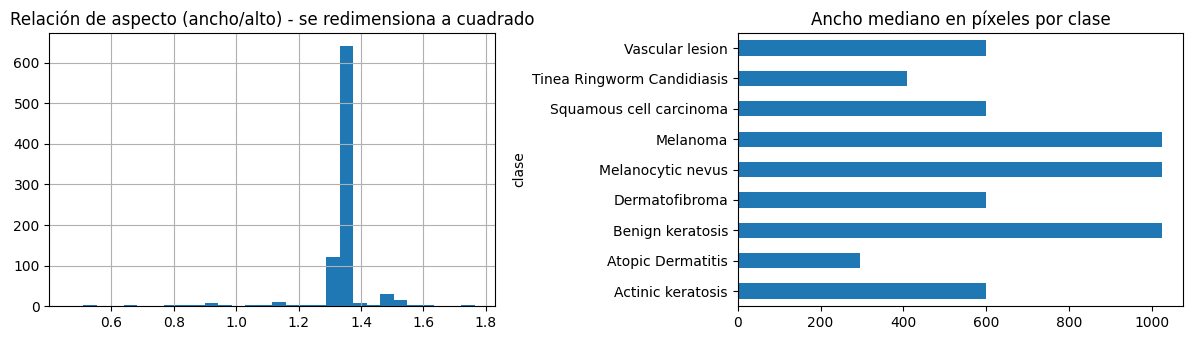

In [5]:
# 1.1 Clases y carpeta de origen
display(pd.crosstab(df["clase"], df["carpeta"], margins=True))
# 1.2 Resoluciones: ¿son todas iguales? ¿dependen de la clase?
print("Resoluciones más frecuentes:"); display(df["res"].value_counts().head(8).to_frame("imágenes").T)
top = df["res"].value_counts().head(5).index
ct = pd.crosstab(df["clase"], df["res"].where(df["res"].isin(top), "otras"), normalize="index").round(2)
print("Fracción de cada clase por resolución:"); display(ct)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df["aspecto"].hist(bins=30, ax=ax[0]); ax[0].set_title("Relación de aspecto (ancho/alto) - se redimensiona a cuadrado")
(df.groupby("clase")["w"].median()).plot.barh(ax=ax[1]); ax[1].set_title("Ancho mediano en píxeles por clase"); plt.tight_layout(); plt.show()

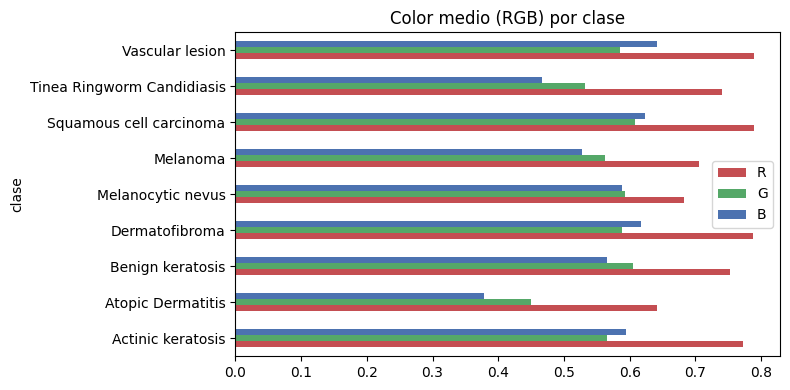

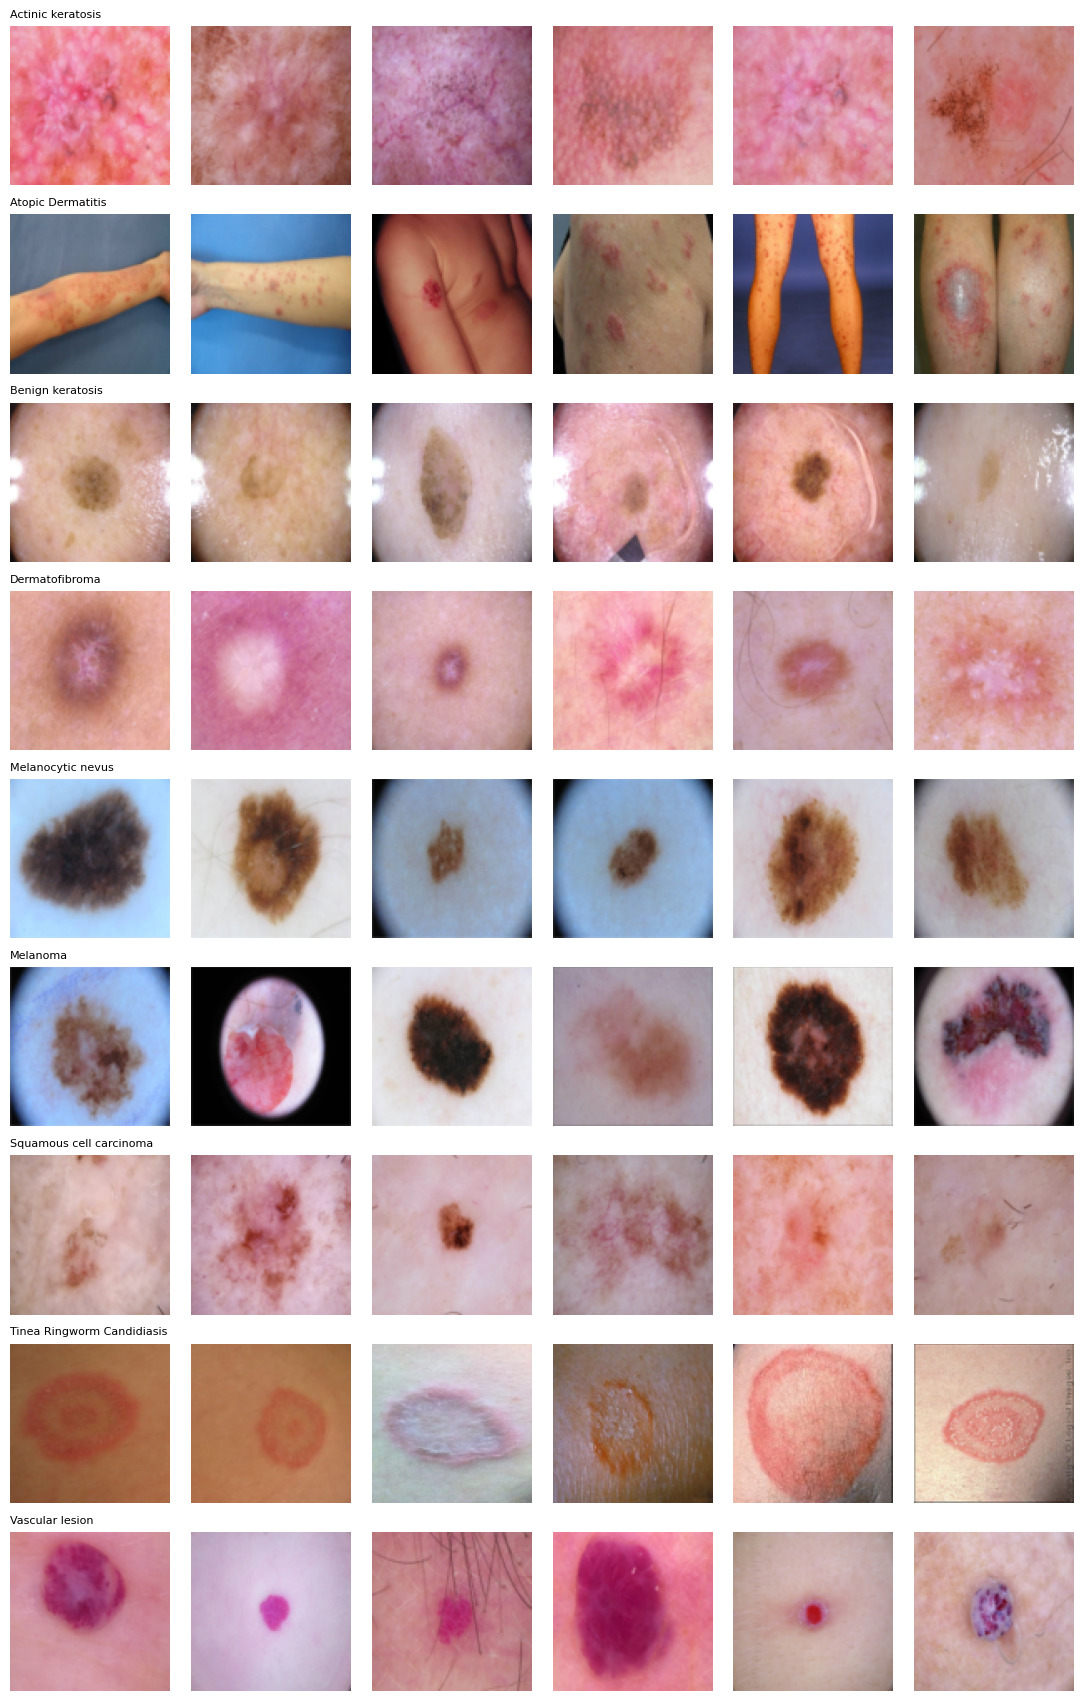

In [6]:
# 1.3 Color medio por clase y ejemplos
mean_rgb = pd.DataFrame(X_U8[32].float().mean((2, 3)).numpy() / 255, columns=["R", "G", "B"]); mean_rgb["clase"] = df["clase"].values
mean_rgb.groupby("clase").mean().plot.barh(color=["#c44e52", "#55a868", "#4c72b0"], figsize=(8, 4), title="Color medio (RGB) por clase"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(11, 1.9 * NUM_CLASSES))
for ci in range(NUM_CLASSES):
    ids = np.where(labels == ci)[0][:6]
    for j, i in enumerate(ids): axes[ci, j].imshow(X_U8[96][i].permute(1, 2, 0)); axes[ci, j].axis("off")
    axes[ci, 0].set_title(class_names[ci], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

### 1.4 Imágenes duplicadas
El dataset viene con una partición `train/`/`val/` propia. Si una misma imagen está en las dos carpetas, la validación **no mide generalización** (el modelo ya vio esas imágenes). Se buscan duplicados **exactos** (mismo hash MD5 del archivo) y se verifica con un hash perceptual (diferencias entre píxeles vecinos de una miniatura) que no queden **casi-duplicados** (recortes o recompresiones).

In [7]:
g = df.groupby("md5")
dup_groups = [idx for _, idx in g.groups.items() if len(idx) > 1]
cross = [idx for idx in dup_groups if df.loc[idx, "carpeta"].nunique() > 1]
print(f"Grupos de imágenes idénticas: {len(dup_groups)} (de los cuales {len(cross)} están repetidos entre train y val)")
print("Por clase:", df.loc[[idx[0] for idx in dup_groups], "clase"].value_counts().to_dict())
print("Conflictos de etiqueta (misma imagen con clases distintas):", sum(df.loc[idx, "y"].nunique() > 1 for idx in dup_groups))

# hash perceptual: miniatura gris 16x17, bit = pixel > vecino derecho (256 bits); distancia de Hamming
gray = X_U8[32].float().mean(1, keepdim=True)
th_ = F.interpolate(gray, size=(16, 17), mode="area")
H = (th_[..., 1:] > th_[..., :-1]).flatten(1).numpy()
near = []
for i in range(len(H)):
    d = (H[i] != H[i + 1:]).sum(1)
    near += [(i, i + 1 + j) for j in np.where(d <= 8)[0]]
near_not_exact = [(i, j) for i, j in near if df.loc[i, "md5"] != df.loc[j, "md5"]]
print(f"Pares con hash perceptual casi igual (<=8 bits de 256): {len(near)} | de ellos NO idénticos por MD5: {len(near_not_exact)}")

Grupos de imágenes idénticas: 34 (de los cuales 33 están repetidos entre train y val)
Por clase: {'Atopic Dermatitis': 22, 'Tinea Ringworm Candidiasis': 12}
Conflictos de etiqueta (misma imagen con clases distintas): 0
Pares con hash perceptual casi igual (<=8 bits de 256): 34 | de ellos NO idénticos por MD5: 0


### ✏️ TUS OBSERVACIONES DEL EDA
Respondan en pocas líneas, con los números de los outputs de arriba:
1. ¿Qué tan desbalanceado está el dataset? ¿Qué cambia respecto de la partición original `train`/`val`?
2. ¿Hay clases que se distinguen por resolución, relación de aspecto o color de fondo? ¿Qué riesgo tiene eso para un modelo que ve las imágenes redimensionadas?
3. ¿Qué duplicados encontraron, en qué clases y por qué importan para la validación? ¿Qué hubiera pasado con la `val_acc` si no los eliminaran?

**Constantes:** no modifiqué ninguna (SIZES, SEEDS, MAX_EPOCHS, PATIENCE, BATCH, AUG_COPIES, SEED_SPLIT=42, SEEDS_FINAL quedaron por defecto). La única diferencia con el enunciado es el hardware: corrí en Colab con GPU T4 (4,3 min en total) y no en CPU.

**1. Desbalance.** El dataset original (878 imágenes) está casi balanceado: ~100 por clase, salvo Atopic Dermatitis (102) y Tinea (76). El cociente entre la clase más grande y la más chica es 1,34. La partición original tampoco era pareja: Tinea tenía 56 en train y 20 en val (26 % en val contra ~20 % de las otras clases). Al quitar duplicados, Atopic baja a 80 y Tinea a 64, y el cociente sube a 1,56 (100/64). El split estratificado 60/20/20 deja train 506, val 169 y test 169, con Tinea en 38/13/13. Con solo 13 imágenes de Tinea en val y en test, el recall de esa clase tiene un error estándar de ~0,13.

**2. Resolución, aspecto y color.** La resolución casi identifica a la clase:
- Actinic keratosis, Dermatofibroma, Squamous cell carcinoma y Vascular lesion son 100 % 600×450.
- Atopic Dermatitis es 100 % 294×222.
- Benign keratosis es 74 % 1024×764, Melanocytic nevus 79 % 1024×768 y Melanoma 56 % 1024×768.
- Tinea es 100 % "otras" resoluciones, con relación de aspecto entre 0,47 y 1,76 (desvío 0,31), mientras que 5 clases tienen aspecto constante (desvío 0,00).

Los nombres de archivo confirman que hay fuentes distintas: las clases ISIC se llaman `ISIC_xxxx`, Atopic usa `n_n.jpg` (102 de 102) y Tinea es de la web (70 de 76 con prefijo `aug_`, más capturas de pantalla). El color medio también separa: Atopic (R 0,64 / G 0,45 / B 0,38) y Tinea (B 0,47) tienen el azul más bajo, y Vascular el más alto (B 0,64).

El riesgo es un atajo. Al redimensionar a cuadrado todas las imágenes, el modelo puede aprender fuente, compresión, deformación de aspecto o cast de color en vez de la lesión. Eso inflaría las clases Atopic y Tinea, y no se transferiría a imágenes de una sola fuente.

**3. Duplicados.** Hay 34 grupos de exactamente 2 imágenes idénticas (MD5): 22 en Atopic y 12 en Tinea, ninguno en las demás clases. 33 grupos cruzan train y val y 1 está dentro de train. No hay conflictos de etiqueta ni casi-duplicados por hash perceptual (0 pares). Importan porque 33 de las 41 imágenes de val de esas dos clases (80 %) ya estaban en train, y en total el 18 % de la val original (33/181) estaba contaminada. Un modelo que memoriza train acierta esas imágenes casi seguro. Estimación gruesa: si el 18 % se acierta y el resto se acierta ~0,65, la val_acc daría 0,18 + 0,82·0,65 ≈ 0,71. Serían ~6 puntos de inflación, más que el error estándar de 0,037, y concentrados justo en las dos clases que ya están confundidas con la fuente.

## 2. Eliminación de duplicados y split estratificado
- Se **elimina una copia de cada imagen duplicada** (se conserva una sola por grupo de MD5).
- Se juntan **todas** las imágenes que quedan (la partición original no sirve: tenía repetidas y no tenía test) y se hace un split **estratificado 60/20/20** con semilla fija. El test no se toca hasta la sección 8.
- Se calcula la **normalización** (media y desvío por canal) **solo con train**.

In [8]:
keep = df.groupby("md5").head(1).index.values            # una imagen por hash
print(f"Imágenes totales: {len(df)} -> sin duplicados: {len(keep)} (se eliminaron {len(df) - len(keep)})")
idx_tr, idx_tmp = train_test_split(keep, test_size=0.4, stratify=labels[keep], random_state=SEED_SPLIT)
idx_va, idx_te  = train_test_split(idx_tmp, test_size=0.5, stratify=labels[idx_tmp], random_state=SEED_SPLIT)
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)}")
print(pd.DataFrame({"train": pd.Series(df.loc[idx_tr, "clase"]).value_counts(), "val": pd.Series(df.loc[idx_va, "clase"]).value_counts(),
                    "test": pd.Series(df.loc[idx_te, "clase"]).value_counts()}).to_string())
assert not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_va, "md5"])) and not (set(df.loc[idx_tr, "md5"]) & set(df.loc[idx_te, "md5"])) and not (set(df.loc[idx_va, "md5"]) & set(df.loc[idx_te, "md5"]))
STATS = {}
for s in SIZES:
    xt = X_U8[s][idx_tr].float() / 255
    STATS[s] = (xt.mean((0, 2, 3)).view(1, 3, 1, 1), xt.std((0, 2, 3)).view(1, 3, 1, 1))
print("mean/std por canal (64px, solo train):", STATS[64][0].flatten().numpy().round(3), STATS[64][1].flatten().numpy().round(3))

Imágenes totales: 878 -> sin duplicados: 844 (se eliminaron 34)
train 506 | val 169 | test 169
                            train  val  test
clase                                       
Actinic keratosis              60   20    20
Atopic Dermatitis              48   16    16
Benign keratosis               60   20    20
Dermatofibroma                 60   20    20
Melanocytic nevus              60   20    20
Melanoma                       60   20    20
Squamous cell carcinoma        60   20    20
Tinea Ringworm Candidiasis     38   13    13
Vascular lesion                60   20    20
mean/std por canal (64px, solo train): [0.743 0.572 0.565] [0.162 0.164 0.186]


## 3. Data augmentation a mano (solo sobre train, después del split)
No se usa ninguna librería de augmentation: las transformaciones están escritas con operaciones de tensores. Cada imagen de **train** se complementa con `AUG_COPIES` copias transformadas **ya generadas** (se calculan una vez, después del split, así que ninguna copia de una imagen de val/test puede filtrarse a train). Val y test **nunca** se aumentan.

Transformaciones disponibles: flips horizontal/vertical, rotaciones de 90° y brillo/contraste aleatorios. Las lesiones dermatoscópicas no tienen orientación privilegiada, pero el **color** es información diagnóstica.

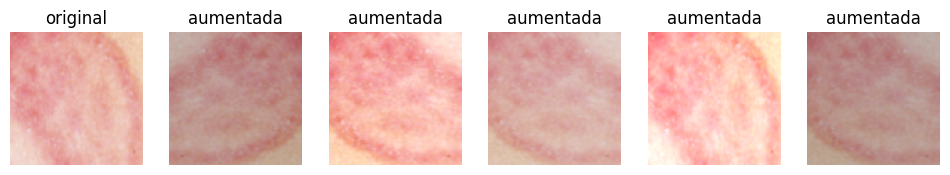

In [9]:
AUGS = {"ninguna": {}, "flips": dict(hflip=True, vflip=True),
        "flips+rot90": dict(hflip=True, vflip=True, rot90=True),
        "flips+rot90+color": dict(hflip=True, vflip=True, rot90=True, color=0.2)}

def augment(x, a):
    # x: tensor float [B,3,H,W] en [0,1]. Cada imagen recibe sus propias transformaciones al azar.
    B = x.shape[0]; x = x.clone()
    if a.get("hflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(3)
    if a.get("vflip"):
        m = torch.rand(B) < 0.5; x[m] = x[m].flip(2)
    if a.get("rot90"):
        k = torch.randint(0, 4, (B,))
        for kv in (1, 2, 3):
            m = k == kv
            if m.any(): x[m] = torch.rot90(x[m], kv, (2, 3))
    if a.get("color"):
        c = a["color"]
        bri = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c; con = 1 + (torch.rand(B, 1, 1, 1) * 2 - 1) * c
        mu = x.mean((1, 2, 3), keepdim=True); x = ((x - mu) * con + mu) * bri
    return x.clamp(0, 1)

TRAIN_SETS = {}
def train_set(size, aug_name):
    # originales de train + AUG_COPIES copias aumentadas de cada una (generadas una vez, con semilla fija)
    key = (size, aug_name)
    if key not in TRAIN_SETS:
        x0, y0 = X_U8[size][idx_tr], Y[idx_tr]
        if aug_name == "ninguna": TRAIN_SETS[key] = (x0, y0)
        else:
            set_seed(1234); xs, ys = [x0], [y0]
            for _ in range(AUG_COPIES): xs.append((augment(x0.float() / 255, AUGS[aug_name]) * 255).round().to(torch.uint8)); ys.append(y0)
            TRAIN_SETS[key] = (torch.cat(xs), torch.cat(ys))
    return TRAIN_SETS[key]

# Vista de una imagen y sus versiones aumentadas
i0 = idx_tr[0]; base = X_U8[96][i0:i0 + 1].float() / 255; set_seed(3)
fig, ax = plt.subplots(1, 6, figsize=(12, 2.3)); ax[0].imshow(base[0].permute(1, 2, 0)); ax[0].set_title("original")
for k in range(1, 6): ax[k].imshow(augment(base, AUGS["flips+rot90+color"])[0].permute(1, 2, 0)); ax[k].set_title("aumentada")
for a in ax: a.axis("off")
plt.show()

## 4. Modelos y entrenamiento
- **`MLP`**: la referencia (Flatten + 2 capas ocultas).
- **`CNN`**: `n_blocks` bloques `Conv2d → BatchNorm → ReLU → MaxPool(2)` con `filters·2^b` canales, y una cabeza `Flatten → Linear(128) → ReLU → Dropout → Linear(clases)`.
- **`rf_full(...)`** calcula el **campo receptivo** teórico de la última capa convolucional.
- **Entrenamiento**: Adam, early stopping sobre `val_loss` restaurando el mejor estado, tiempo por época medido.

In [10]:
class MLP(nn.Module):
    def __init__(self, size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(3 * size * size, 512), nn.ReLU(),
                                 nn.Linear(512, 128), nn.ReLU(), nn.Linear(128, num_classes))
    def forward(self, x): return self.net(x)

class CNN(nn.Module):
    def __init__(self, size, n_blocks=3, filters=16, kernel=3, use_bn=True, dropout=0.2, num_classes=NUM_CLASSES):
        super().__init__()
        layers, cin = [], 3
        for b in range(n_blocks):
            cout = filters * 2 ** b
            layers += [nn.Conv2d(cin, cout, kernel, padding=kernel // 2, bias=not use_bn)]
            if use_bn: layers += [nn.BatchNorm2d(cout)]
            layers += [nn.ReLU(), nn.MaxPool2d(2)]
            cin = cout
        self.features = nn.Sequential(*layers)
        fs = size // 2 ** n_blocks                       # lado del mapa de activación después de los n_blocks pooling
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(cin * fs * fs, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))
    def forward(self, x): return self.head(self.features(x))

def rf_full(n_blocks, kernel):
    # campo receptivo de la última conv: cada conv suma (k-1)*salto; cada maxpool(2) suma 1*salto y duplica el salto
    r, j = 1, 1
    for b in range(n_blocks):
        r += (kernel - 1) * j
        if b < n_blocks - 1: r += 1 * j; j *= 2
    return r
def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def norm_batch(x_u8, size):
    mu, sd = STATS[size]; return ((x_u8.float() / 255 - mu) / sd).to(device)

def get_eval_batch(size, ids, shift=0):
    x = X_U8[size][ids].float() / 255
    if shift:   # traslación circular aleatoria (solo para medir robustez a traslaciones)
        x = torch.stack([torch.roll(xi, shifts=(int(np.random.randint(-shift, shift + 1)), int(np.random.randint(-shift, shift + 1))), dims=(1, 2)) for xi in x])
    mu, sd = STATS[size]; return ((x - mu) / sd).to(device), Y[ids].to(device)

@torch.no_grad()
def evaluate(model, ids, size, shift=0):
    model.eval(); L, P = 0.0, []
    for i in range(0, len(ids), 256):
        xb, yb = get_eval_batch(size, ids[i:i + 256], shift)
        out = model(xb); L += F.cross_entropy(out, yb, reduction="sum").item(); P.append(out.argmax(1).cpu())
    P = torch.cat(P).numpy()
    return L / len(ids), accuracy_score(labels[ids], P), P

def make_model(cfg):
    if cfg["model"] == "mlp": return MLP(cfg["size"])
    return CNN(cfg["size"], cfg["n_blocks"], cfg["filters"], cfg["kernel"], cfg.get("use_bn", True), cfg["dropout"])

def fit(cfg, seed):
    set_seed(seed); model = make_model(cfg).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"]); size = cfg["size"]
    Xtr, Ytr = train_set(size, cfg["aug"])
    h = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[], epoch_time=[])
    best, best_ep, best_state, bad = 1e9, 0, None, 0
    for ep in range(MAX_EPOCHS):
        t0 = time.time(); model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue
            opt.zero_grad(); F.cross_entropy(model(norm_batch(Xtr[ids], size)), Ytr[ids].to(device)).backward(); opt.step()
        if device.type == "cuda": torch.cuda.synchronize()
        h["epoch_time"].append(time.time() - t0)
        trl, tra, _ = evaluate(model, idx_tr, size)       # train ORIGINAL en modo eval (sin dropout ni copias aumentadas)
        vl, va, _ = evaluate(model, idx_va, size)
        h["train_loss"].append(trl); h["train_acc"].append(tra); h["val_loss"].append(vl); h["val_acc"].append(va)
        if vl < best - 1e-4: best, best_ep, best_state, bad = vl, ep, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    h.update(best_epoch=best_ep + 1, n_epochs=len(h["val_loss"]), n_params=n_params(model))
    return model, h

def run(cfg, seeds=SEEDS):
    # entrena la config con varias semillas y resume (media ± desvío)
    ms, hs = [], []
    for s in seeds:
        m, h = fit(cfg, s); ms.append(m); hs.append(h)
    be = [h["best_epoch"] - 1 for h in hs]
    va = [h["val_acc"][e] for h, e in zip(hs, be)]
    r = dict(val_acc=np.mean(va), val_acc_std=np.std(va), train_acc=np.mean([h["train_acc"][e] for h, e in zip(hs, be)]),
             val_loss=np.mean([min(h["val_loss"]) for h in hs]), best_epoch=np.mean([h["best_epoch"] for h in hs]),
             t_epoca_s=np.mean([np.mean(h["epoch_time"]) for h in hs]), t_total_s=np.mean([sum(h["epoch_time"]) for h in hs]), params=hs[0]["n_params"])
    r["brecha"] = r["train_acc"] - r["val_acc"]
    return r, ms, hs

BASE = dict(model="cnn", size=64, n_blocks=3, filters=16, kernel=3, dropout=0.2, lr=3e-3, aug="ninguna")
print("Parámetros CNN base (64px):", n_params(CNN(64)), "| MLP (64px):", n_params(MLP(64)), "| campo receptivo CNN base:", rf_full(3, 3), "px")

Parámetros CNN base (64px): 549273 | MLP (64px): 6358793 | campo receptivo CNN base: 18 px


### 4.1 Cómo se transforma una imagen dentro de la CNN
La tabla muestra, capa por capa, la **forma de la salida** `(canales, alto, ancho)` y la **cantidad de parámetros** de la CNN base con una imagen de 64×64.

In [11]:
def trace(model, size):
    model.eval(); x = torch.zeros(1, 3, size, size); rows = []
    for i, l in enumerate(list(model.features) + list(model.head)):
        x = l(x); rows.append(dict(capa=i, tipo=l.__class__.__name__, detalle=str(l)[:46], salida=tuple(x.shape[1:]), params=sum(p.numel() for p in l.parameters())))
    return pd.DataFrame(rows)
tr = trace(CNN(64), 64); display(tr); print("Total de parámetros:", tr["params"].sum())

,capa,tipo,detalle,salida,params
0,0,Conv2d,"Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1","(16, 64, 64)",432
1,1,BatchNorm2d,"BatchNorm2d(16, eps=1e-05, momentum=0.1, affin","(16, 64, 64)",32
2,2,ReLU,ReLU(),"(16, 64, 64)",0
3,3,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(16, 32, 32)",0
4,4,Conv2d,"Conv2d(16, 32, kernel_size=(3, 3), stride=(1,","(32, 32, 32)",4608
5,5,BatchNorm2d,"BatchNorm2d(32, eps=1e-05, momentum=0.1, affin","(32, 32, 32)",64
6,6,ReLU,ReLU(),"(32, 32, 32)",0
7,7,MaxPool2d,"MaxPool2d(kernel_size=2, stride=2, padding=0,","(32, 16, 16)",0
8,8,Conv2d,"Conv2d(32, 64, kernel_size=(3, 3), stride=(1,","(64, 16, 16)",18432
9,9,BatchNorm2d,"BatchNorm2d(64, eps=1e-05, momentum=0.1, affin","(64, 16, 16)",128


Total de parámetros: 549273


### ✏️ EXPLICÁ EL CÓDIGO CONVOLUCIONAL
Con la clase `CNN` y la tabla de arriba, expliquen con sus palabras (y verificando con los números de la tabla):
1. **`padding=kernel // 2`**: ¿qué pasa con el alto y el ancho al aplicar la convolución? ¿Qué pasaría con `padding=0`? ¿Cómo se ve en la tabla?
2. **`MaxPool2d(2)`**: ¿qué hace con la forma de salida y qué información conserva? ¿Qué relación tiene con `fs = size // 2 ** n_blocks`?
3. **Parámetros:** calculen a mano cuántos parámetros tiene la segunda `Conv2d` (16 → 32 canales, kernel 3) y la primera `Linear` de la cabeza. Verifiquen con la tabla. ¿Cuál de las dos domina el total y por qué?
4. **`bias=not use_bn`:** ¿por qué la convolución no necesita sesgo cuando le sigue una BatchNorm?
5. **`filters * 2 ** b`:** ¿por qué se duplican los canales mientras se reduce la resolución a la mitad?
6. **`rf_full`:** reproduzcan a mano el campo receptivo de 18 px para 3 bloques con kernel 3 y expliquen qué significa ese número respecto de una imagen de 64 px.

**1. `padding=kernel // 2`.** El tamaño de salida de una convolución con stride 1 es `H_out = H + 2p − k + 1`. Con k=3 y p=1 queda `H_out = H`. Por eso en la tabla la primera `Conv2d` pasa de 3×64×64 a (16, 64, 64): cambian los canales, no el alto ni el ancho. Con `padding=0` saldría 62×62, y con 3 convoluciones se perderían 2 píxeles por capa (el borde se vería menos veces que el centro). Además `fs = size // 2**n_blocks` y la entrada de la `Linear` dejarían de coincidir con la forma real. `k // 2` conserva el tamaño solo para kernels impares (3, 5, 7, los que usamos).

**2. `MaxPool2d(2)`.** Divide alto y ancho por 2 y deja los canales igual: (16,64,64) → (16,32,32), y así hasta (64,8,8). De cada ventana de 2×2 se queda con la activación más fuerte y descarta en qué posición de la ventana estaba. Eso da algo de invarianza a traslaciones chicas y reduce el cómputo 4× por capa. Con n_blocks=3 hay 3 pooling, por eso `fs = 64 // 2**3 = 8`, que coincide con la tabla (64,8,8). Para tamaños no divisibles por 2**n se descarta la última fila o columna (división entera).

**3. Parámetros.** Segunda conv (16→32, k=3): 32·16·3·3 = **4.608** (sin bias), igual que la tabla. Primera `Linear`: 4096·128 + 128 = **524.416**, también igual. La `Linear` domina: son 524.416 de 549.273 (95,5 %). Las tres convoluciones suman solo 23.472 porque un kernel pequeño se comparte en todas las posiciones. La `Linear` es densa sobre las 64·8·8 = 4096 características aplanadas, y cada una tiene su propio peso hacia cada una de las 128 unidades.

**4. `bias=not use_bn`.** La BatchNorm resta la media del batch por canal, así que cualquier constante que sume el bias se cancela en esa resta. El desplazamiento lo aporta el β de la BN. Dejar el bias sería redundante (en la tabla la primera conv tiene 432 = 16·3·9 parámetros y no 448).

**5. `filters * 2**b`.** Cada pooling reduce las posiciones 4×. Si duplicamos los canales, las activaciones por capa pasan de 16·64·64 = 65.536 a 32·32·32 = 32.768 y a 64·16·16 = 16.384, es decir, la memoria baja a la mitad por bloque en vez de a la cuarta parte. En las capas profundas hay menos posiciones, pero cada unidad combina patrones más variados (bordes → texturas → formas), y se compensa con más canales.

**6. Campo receptivo.** Con `rf_full`: r=1, salto j=1. Bloque 0: +(3−1)·1 → 3; pool: +1·1 → 4, j=2. Bloque 1: +2·2 → 8; pool: +1·2 → 10, j=4. Bloque 2: +2·4 → **18** (el último pool no se cuenta). Cada unidad de la última conv "ve" una ventana de 18×18 px: 28 % del lado de una imagen de 64 px, y 7,9 % del área. Ninguna unidad ve la lesión completa. La integración global la hace la `Linear`, que sí mira los 8×8 mapas. (Es el campo receptivo teórico; el efectivo suele ser menor.)

### 4.2 Chequeo rápido: el modelo aprende
Se entrena la CNN base con una semilla y se grafican curvas. Sirve para verificar que el pipeline funciona antes de correr los experimentos.

mejor época 11 | val_acc 0.663 | train_acc 0.794 | 0.15 s/época | total 11s


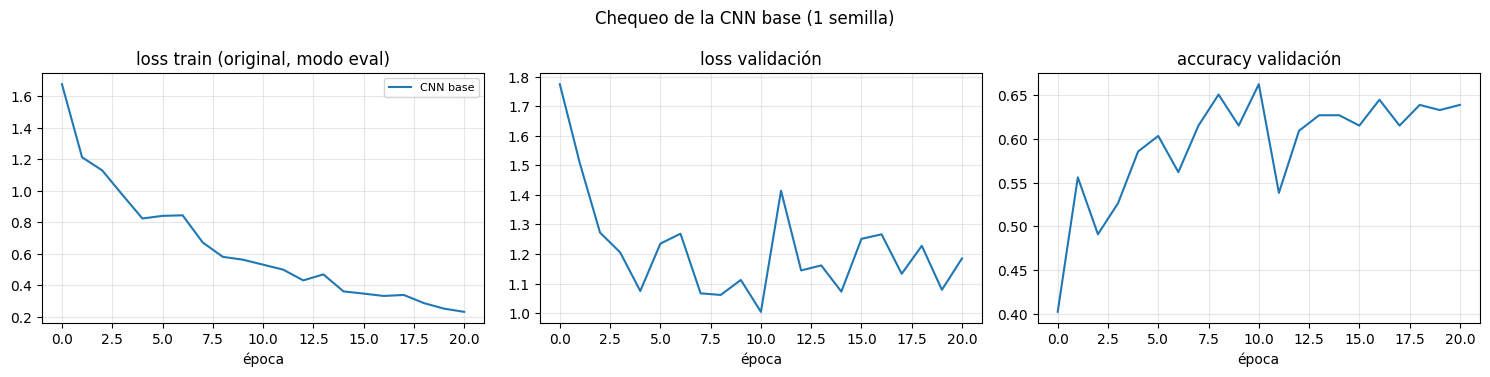

In [12]:
def plot_curves(hists, title):
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for name, h in hists.items():
        ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["val_loss"], label=name); ax[2].plot(h["val_acc"], label=name)
    for a, t in zip(ax, ["loss train (original, modo eval)", "loss validación", "accuracy validación"]): a.set_title(t); a.set_xlabel("época"); a.grid(alpha=.3)
    ax[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
t0 = time.time(); _, h = fit(BASE, 0)
print(f"mejor época {h['best_epoch']} | val_acc {h['val_acc'][h['best_epoch']-1]:.3f} | train_acc {h['train_acc'][h['best_epoch']-1]:.3f} | {np.mean(h['epoch_time']):.2f} s/época | total {time.time()-t0:.0f}s")
plot_curves({"CNN base": h}, "Chequeo de la CNN base (1 semilla)")

## 5. De la MLP a la CNN
Misma resolución, mismo split, mismo criterio de parada, 3 semillas. Además de val_acc se mide:
- **Parámetros y tiempo por época.**
- **Robustez a traslaciones**: se evalúa el modelo ya entrenado sobre validación con imágenes **trasladadas** al azar hasta ±`SHIFT` px (la convolución es equivariante a traslaciones y con pooling aproximadamente invariante; la MLP no tiene esa propiedad).

,modelo,params,val_acc,std,train_acc,brecha,mejor_epoca,t_epoca_s,val_acc_trasladada,caida_por_traslacion
0,MLP 32px,1640201,0.4951,0.0388,0.7378,0.2427,5.0000,0.0368,0.4346,0.0605
1,MLP 64px,6358793,0.5247,0.0433,0.7042,0.1796,6.6667,0.0570,0.4372,0.0874
2,CNN 32px,156057,0.6726,0.0283,0.8182,0.1456,8.3333,0.0618,0.5871,0.0855
3,CNN 64px,549273,0.6410,0.0148,0.7721,0.1310,11.6667,0.0866,0.5562,0.0848


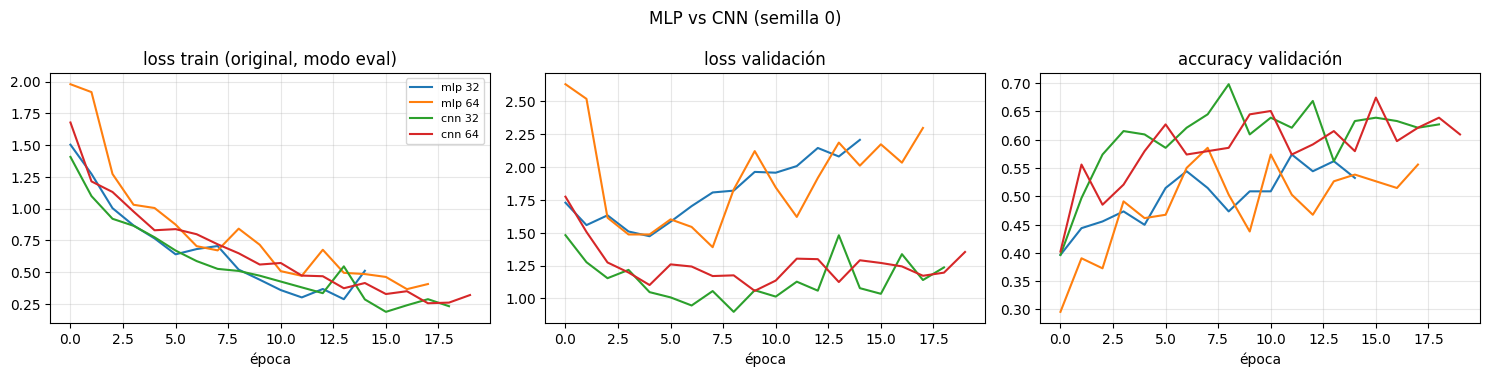

Referencia: azar = 0.111 | error estándar binomial de un accuracy ~0.5 con 169 imágenes de val = 0.038


In [13]:
SHIFT = {32: 4, 64: 8}
rows, store = [], {}
for model_name, size in [("mlp", 32), ("mlp", 64), ("cnn", 32), ("cnn", 64)]:
    cfg = {**BASE, "model": model_name, "size": size}
    r, ms, hs = run(cfg)
    clean = [evaluate(m, idx_va, size)[1] for m in ms]; shifted = [np.mean([evaluate(m, idx_va, size, shift=SHIFT[size])[1] for _ in range(3)]) for m in ms]
    rows.append(dict(modelo=f"{model_name.upper()} {size}px", params=r["params"], val_acc=r["val_acc"], std=r["val_acc_std"], train_acc=r["train_acc"],
                     brecha=r["brecha"], mejor_epoca=r["best_epoch"], t_epoca_s=r["t_epoca_s"],
                     val_acc_trasladada=np.mean(shifted), caida_por_traslacion=np.mean(clean) - np.mean(shifted)))
    store[f"{model_name} {size}"] = hs[0]
tab_mlp_cnn = pd.DataFrame(rows); display(tab_mlp_cnn.round(4))
plot_curves(store, "MLP vs CNN (semilla 0)")
print(f"Referencia: azar = {1/NUM_CLASSES:.3f} | error estándar binomial de un accuracy ~0.5 con {len(idx_va)} imágenes de val = {np.sqrt(.25/len(idx_va)):.3f}")

### ✏️ TU ANÁLISIS 1 - De la MLP a la CNN
1. Compará MLP y CNN en **parámetros, val_acc (± desvío), brecha train-val, tiempo por época y época de convergencia**. ¿La diferencia de val_acc supera el ruido entre semillas y el error estándar de la validación?
2. ¿Por qué la MLP necesita tantos más parámetros? Calculá a mano cuántos parámetros tiene la primera capa de la MLP a 32 y a 64 px y explicá qué pasaría a 224 px. ¿Qué propiedades de la convolución (pesos compartidos, conectividad local) cambian ese número?
3. Mirá la **caída por traslación**: ¿cuál de los dos modelos se degrada menos y por qué? ¿Es coherente con la teoría de equivarianza/invarianza, o el ruido no permite concluir?
4. ¿Qué rol cumple la normalización de entrada acá (mencionen cómo se calculó) y qué esperarían si no se hiciera?

**1. Comparación (3 semillas, validación de 169 imágenes; error estándar binomial ≈ 0,037):**

| Modelo | Params | val_acc ± std | Brecha | Época mejor | s/época |
|---|---|---|---|---|---|
| MLP 32px | 1.640.201 | 0,495 ± 0,039 | 0,243 | 5,0 | 0,037 |
| MLP 64px | 6.358.793 | 0,525 ± 0,043 | 0,180 | 6,7 | 0,057 |
| CNN 32px | 156.057 | 0,673 ± 0,028 | 0,146 | 8,3 | 0,062 |
| CNN 64px | 549.273 | 0,641 ± 0,015 | 0,131 | 11,7 | 0,087 |

A igual resolución la CNN gana +0,178 (32 px) y +0,117 (64 px). Eso es 3 a 5 veces el desvío entre semillas y supera 3 errores estándar de val, así que es una diferencia real. La CNN usa 10,5× (32 px) y 11,6× (64 px) menos parámetros, tiene menor brecha (0,13–0,15 contra 0,18–0,24) y converge más tarde (época 8–12 contra 5–7): la MLP empieza a sobreajustar antes. Cuesta ~1,5× más por época, pero en una T4 (la GPU que estoy usando) son centésimas de segundo y no es relevante. Un detalle: la misma CNN 64px dio 0,625 y 0,657 en las secciones 6 y 7, así que ±0,03 es un piso realista de ruido.

**2. Por qué la MLP necesita tantos parámetros.** Su primera capa conecta cada píxel con cada una de las 512 unidades: 3·32·32·512 + 512 = **1.573.376** a 32 px y 3·64·64·512 + 512 = **6.291.968** a 64 px (cuadruplica al duplicar el lado). A 224 px serían 3·224²·512 + 512 ≈ **77 millones** solo en esa capa. La convolución usa conectividad local (cada unidad mira un parche de k×k) y pesos compartidos (el mismo filtro en todas las posiciones), así que sus parámetros dependen de canales y kernel y no de la resolución. Las 3 convs de la base suman 23.472 parámetros a cualquier tamaño. Lo que sí crece con la resolución es la `Linear` de la cabeza (a 224 px, 64·28²·128 ≈ 6,4M): un `GlobalAveragePooling` lo evitaría.

**3. Traslaciones** (roll circular de hasta ±4 px a 32 y ±8 px a 64, es decir, 12,5 % del lado):

| Modelo | val limpia | trasladada | caída | caída relativa |
|---|---|---|---|---|
| MLP 32 | 0,495 | 0,435 | 0,060 | 12 % |
| MLP 64 | 0,525 | 0,437 | 0,087 | 17 % |
| CNN 32 | 0,673 | 0,587 | 0,085 | 13 % |
| CNN 64 | 0,641 | 0,556 | 0,085 | 13 % |

**Los datos no respaldan que la CNN sea más robusta:** las caídas absolutas son parecidas (0,06–0,09), las diferencias entre modelos (≤ 0,03) están dentro del ruido, y la MLP 32 es la que menos cae. La CNN se mantiene ~0,12–0,15 por encima en valor absoluto, pero eso viene de que ya partía más arriba. Explicaciones posibles, que no probamos: la equivarianza vale para las convoluciones, pero la `Linear` posterior sobre el mapa aplanado es sensible a la posición; el MaxPool solo da invarianza a corrimientos chicos (< 2^n_bloques px); el roll circular mete bordes artificiales; y ningún modelo se entrenó con traslaciones. Con 3 semillas y 169 imágenes no podemos confirmar ni descartar la teoría.

**4. Normalización.** Media y desvío por canal se calcularon **solo con train** (64 px: media [0,743; 0,572; 0,565], desvío [0,162; 0,164; 0,186]) y se aplicaron igual a val y test. Sin normalizar, las entradas en [0,1] tendrían media ~0,6 y el canal rojo sistemáticamente más alto, con lo que las preactivaciones de la primera capa estarían sesgadas y correlacionadas, y Adam con lr=3e-3 tendería a converger peor, sobre todo en la MLP (que no tiene BN). Es lo que esperamos, no lo medimos. Calcularla con val o test sería una fuga (chica, pero rompe la regla).

## 6. Decisiones de arquitectura convolucional
Se parte de la CNN base y se cambia **un factor a la vez** (3 semillas cada uno): profundidad, tamaño del kernel, cantidad de filtros y resolución de entrada. Se reporta además el **campo receptivo** teórico y los parámetros (que incluyen la capa `Linear` de la cabeza, cuyo tamaño depende de la resolución y la profundidad).

,variante,campo_receptivo,params,val_acc,val_acc_std,train_acc,brecha,best_epoch,t_epoca_s,t_total_s
0,"base (3 bloques, k=3, 16 filtros, 64px)",18,549273,0.6252,0.0201,0.7424,0.1172,8.6667,0.0793,1.4749
1,2 bloques,8,1055001,0.6134,0.0283,0.7931,0.1797,11.3333,0.0651,1.3861
2,4 bloques,38,361113,0.6667,0.0148,0.8432,0.1765,17.3333,0.0845,2.3185
3,kernel 5,32,591001,0.5976,0.0365,0.7648,0.1672,13.3333,0.0865,2.0158
4,kernel 7,46,653593,0.5996,0.0402,0.6897,0.0901,14.3333,0.1095,2.6665
5,8 filtros,18,269521,0.6647,0.0170,0.8768,0.2121,11.3333,0.0773,1.6493
6,32 filtros,18,1143337,0.6174,0.0074,0.7675,0.1501,12.6667,0.1132,2.5647
7,32 px,18,156057,0.6450,0.0242,0.8208,0.1758,10.0000,0.0555,1.1094
8,96 px,18,1204633,0.5996,0.0201,0.7866,0.1870,15.6667,0.1545,4.0949


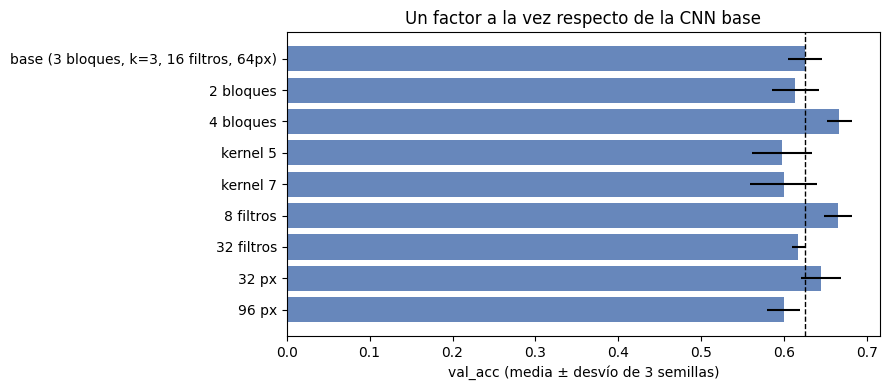

In [14]:
ARCH_VARIANTS = {
    "base (3 bloques, k=3, 16 filtros, 64px)": {},
    "2 bloques": dict(n_blocks=2), "4 bloques": dict(n_blocks=4),
    "kernel 5": dict(kernel=5), "kernel 7": dict(kernel=7),
    "8 filtros": dict(filters=8), "32 filtros": dict(filters=32),
    "32 px": dict(size=32), "96 px": dict(size=96),
}
rows, arch_cfgs, arch_hist = [], {}, {}
for name, delta in ARCH_VARIANTS.items():
    cfg = {**BASE, **delta}; r, ms, hs = run(cfg)
    rows.append(dict(variante=name, campo_receptivo=rf_full(cfg["n_blocks"], cfg["kernel"]), **r)); arch_cfgs[name] = cfg; arch_hist[name] = hs[0]
tab_arch = pd.DataFrame(rows)
display(tab_arch[["variante", "campo_receptivo", "params", "val_acc", "val_acc_std", "train_acc", "brecha", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tab_arch["variante"], tab_arch["val_acc"], xerr=tab_arch["val_acc_std"], color="#4c72b0", alpha=.85); ax.invert_yaxis()
ax.axvline(tab_arch["val_acc"].iloc[0], color="k", ls="--", lw=1); ax.set_xlabel("val_acc (media ± desvío de 3 semillas)"); ax.set_title("Un factor a la vez respecto de la CNN base"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 2 - Arquitectura convolucional
1. ¿Qué factores cambian la val_acc **más allá del ruido entre semillas** (desvío de la tabla) y cuáles no? Sean explícitos sobre qué diferencias son pequeñas respecto del ruido.
2. **Profundidad y kernel:** relacionen el campo receptivo con el tamaño de la imagen y con lo que se quiere detectar en una lesión (bordes, texturas, asimetría global). ¿Qué esperaban de agregar bloques o agrandar el kernel y qué se observó? Comparen costo (parámetros y tiempo) vs. ganancia.
3. **Resolución de entrada (32/64/96):** ¿cómo cambia la cantidad de parámetros de la capa `Linear` de la cabeza y por qué? ¿Qué se gana (detalle disponible) y qué se pierde (cómputo, campo receptivo relativo a la imagen)? Con tan pocas imágenes por clase, ¿qué límite tiene este experimento?
4. ¿Qué no se puede concluir con un diseño de "un factor a la vez" y 3 semillas?

**Resultados (3 semillas; base = 0,625 ± 0,020; error estándar binomial de val ≈ 0,037):**

| Variante | RF | Params | val_acc ± std | Δ vs base | Brecha | s/época |
|---|---|---|---|---|---|---|
| base (3 bl, k3, 16f, 64px) | 18 | 549k | 0,625 ± 0,020 | — | 0,117 | 0,079 |
| 2 bloques | 8 | 1.055k | 0,613 ± 0,028 | −0,012 | 0,180 | 0,065 |
| 4 bloques | 38 | 361k | 0,667 ± 0,015 | **+0,041** | 0,177 | 0,084 |
| kernel 5 | 32 | 591k | 0,598 ± 0,036 | −0,028 | 0,167 | 0,087 |
| kernel 7 | 46 | 654k | 0,600 ± 0,040 | −0,026 | 0,090 | 0,110 |
| 8 filtros | 18 | 270k | 0,665 ± 0,017 | **+0,040** | 0,212 | 0,077 |
| 32 filtros | 18 | 1.143k | 0,617 ± 0,007 | −0,008 | 0,150 | 0,113 |
| 32 px | 18 | 156k | 0,645 ± 0,024 | +0,020 | 0,176 | 0,056 |
| 96 px | 18 | 1.205k | 0,600 ± 0,020 | −0,026 | 0,187 | 0,155 |

**1. Qué supera el ruido.** Casi nada con claridad. Los dos mejores (4 bloques y 8 filtros, +0,04) están a ~1 error estándar de val y a ~2 desvíos entre semillas. Además, la misma config base dio 0,641, 0,625 y 0,657 en tres secciones del notebook con las mismas semillas: ese rango de 0,03 es comparable a todos los efectos medidos, y solo un +0,04 queda apenas fuera de él. Las demás diferencias (−0,008 a −0,028 y +0,020) son indistinguibles del ruido. Lo más que se puede decir es que hay una señal débil a favor de 4 bloques y menos filtros, y en contra de kernels grandes y de 96 px. La evidencia de que 4 bloques re-medido bajó (0,667 en sección 6 → 0,649 al re-entrenar en la sección 8) es consistente con una parte de "maldición del ganador".

**2. Profundidad y kernel.** El RF crece de 8 px (2 bloques, 12 % del lado) a 18 (28 %) y 38 (59 %). Con 2 bloques una unidad ve solo microtextura; con 4 ya abarca más de la mitad de la lesión, lo que ayuda para asimetría, bordes y forma global y no solo textura. Esperábamos mejora al agregar bloques y se vio +0,04, dentro de lo débil. Una sorpresa de costo: más bloques usan **menos** parámetros (361k contra 549k contra 1.055k), porque cada pooling reduce el mapa que entra a la `Linear` (4 bloques: 128·4·4 = 2048 características; 2 bloques: 32·16·16 = 8192). Kernel 5 y 7 llegan a RF 32 y 46 con un solo paso, pero no mejoraron (−0,028 y −0,026), tienen más desvío (0,036–0,040) y cuestan más (kernel 7: 0,110 s/época contra 0,079). Apilar 3×3 consigue RF 38 con 361k parámetros contra 654k del kernel 7 (RF 46), además de agregar no linealidades. En resumen: 4 bloques cuesta lo mismo en tiempo (0,084 contra 0,079 s/época) y menos parámetros, y es la opción dominante.

**3. Resolución.** Las convs ocupan 23.472 parámetros a cualquier tamaño; cambia el lado de la `Linear`: 128·(fs²·64)... precisamente 4096·128 = 524k a 64 px, 1024·128 = 131k a 32 px y 9216·128 = 1,18M a 96 px (fs = 4, 8, 12). Por eso los totales son 156k, 549k y 1,2M. A 32 px cada unidad ve una fracción mucho mayor de la imagen (RF 18/32 = 56 % contra 28 % a 64 px y 19 % a 96 px), y el cómputo baja a casi la mitad por época (0,056 contra 0,079 y 0,155 s); se pierde detalle fino (textura, red pigmentaria). Los resultados dicen que 32 px no es peor (+0,020) y 96 px es lo peor (−0,026, brecha 0,187), pero con 506 imágenes de train y 169 de val no podemos separar eso del ruido. Una explicación posible, sin probar, es que más resolución agrega parámetros y detalle que no se puede aprender con tan pocos datos. El límite del experimento: 3 semillas, una sola partición, y las imágenes originales de 600–1024 px se aplastan a cuadrado, con lo que la comparación 64 contra 96 mide más el preprocesamiento que la información.

**4. Qué no se puede concluir.** Un factor a la vez no dice nada sobre interacciones (por ejemplo, 96 px quizás necesite 4–5 bloques para mantener el RF relativo; 8 filtros quizás necesite otro lr). Tampoco hay un óptimo: son puntos sueltos. Con 3 semillas el propio desvío está mal estimado, y con la misma val usada para ~14 decisiones el error de selección no es despreciable. La brecha tampoco sigue la capacidad de forma limpia (8 filtros tiene brecha 0,21 y kernel 7 tiene 0,09), así que no la interpretamos.

## 7. Data augmentation
Con aproximadamente 60 imágenes por clase en train, el overfitting es esperable. Se comparan cuatro niveles de augmentation (los de la sección 3) con la CNN base y 3 semillas. En cada caso, **train queda con las imágenes originales más `AUG_COPIES` copias aumentadas de cada una**; val y test no se tocan.

,augmentation,n_train,val_acc,val_acc_std,train_acc,brecha,val_loss,best_epoch,t_epoca_s,t_total_s
0,ninguna,506,0.6568,0.0338,0.8037,0.1469,0.9948,12.3333,0.0811,1.7980
1,flips,1518,0.6430,0.0343,0.8188,0.1758,1.0248,9.0000,0.2206,4.1851
2,flips+rot90,1518,0.6371,0.0343,0.8109,0.1739,1.0749,9.6667,0.2206,4.3442
3,flips+rot90+color,1518,0.6252,0.0311,0.8149,0.1896,0.9936,10.3333,0.2306,4.7802


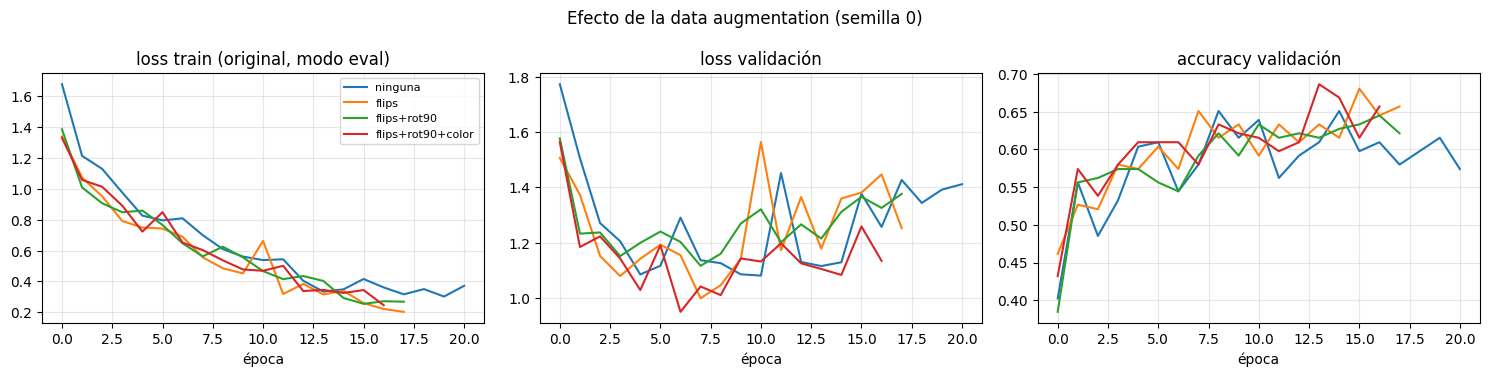

In [15]:
rows, aug_hist = [], {}
for name in AUGS:
    cfg = {**BASE, "aug": name}; r, ms, hs = run(cfg)
    rows.append(dict(augmentation=name, n_train=len(train_set(64, name)[0]), **r)); aug_hist[name] = hs[0]
tab_aug = pd.DataFrame(rows)
display(tab_aug[["augmentation", "n_train", "val_acc", "val_acc_std", "train_acc", "brecha", "val_loss", "best_epoch", "t_epoca_s", "t_total_s"]].round(4))
plot_curves(aug_hist, "Efecto de la data augmentation (semilla 0)")

### ✏️ TU ANÁLISIS 3 - Overfitting y augmentation
1. Demostrá el overfitting de la CNN sin augmentation **con números**: brecha train-val, época donde la `val_loss` empieza a subir.
2. ¿Qué cambia con cada nivel de augmentation sobre la **brecha**, la `val_loss`, la `val_acc`, la **época de convergencia** y el **tiempo total**? ¿Por qué cada época cuesta más con augmentation? ¿Cuál de las mejoras supera el ruido entre semillas?
3. Discutan desde el dominio (dermatología) qué transformaciones tienen sentido y cuáles podrían **destruir información** (por ejemplo, el color o la escala). ¿Qué otras augmentations probarían?
4. ¿Por qué es importante que la augmentation se haga **después** del split y **solo en train**? ¿Qué pasaría con las métricas si se aumentara antes de dividir?
5. Compará con lo que vieron en el TP3: ¿qué diferencia hay entre regularizar con dropout/L2 (restricciones sobre los pesos) y con augmentation (más datos sintéticos)?

**1. Overfitting con números (CNN base, sin augmentation).** train_acc 0,804 contra val_acc 0,657: brecha 0,147 (en las otras corridas del mismo modelo, 0,12–0,13). Esa brecha se mide en el mejor estado restaurado por early stopping, así que subestima el sobreajuste real. En la semilla 0 la val_loss mínima está en la **época 11** (1,081); el entrenamiento siguió 10 épocas más por la paciencia, y en la época 21 la train_loss bajó a 0,372 mientras la val_loss subió a 1,412 (+31 %) y la val_acc cayó de 0,639 a 0,574 (con train_acc 0,848). En el promedio de 3 semillas, la mejor época es la 12,3. La MLP lo hace antes y más fuerte (val_loss mínima en época 8 con 1,39, y 2,30 en la época 18).

**2. Efecto de cada nivel (3 semillas; train 506 → 1.518):**

| Aug | val_acc ± std | Brecha | val_loss | Mejor época | s/época | Total |
|---|---|---|---|---|---|---|
| ninguna | 0,657 ± 0,034 | 0,147 | 0,995 | 12,3 | 0,081 | 1,8 s |
| flips | 0,643 ± 0,034 | 0,176 | 1,025 | 9,0 | 0,221 | 4,2 s |
| flips+rot90 | 0,637 ± 0,034 | 0,174 | 1,075 | 9,7 | 0,221 | 4,3 s |
| +color | 0,625 ± 0,031 | 0,190 | 0,994 | 10,3 | 0,231 | 4,8 s |

**Ninguna augmentation mejoró**: la val_acc bajó entre 0,014 y 0,032 y la brecha **subió** de 0,147 a 0,17–0,19, el opuesto de lo esperado. Todas las diferencias están dentro del ruido (std 0,031–0,034; error estándar de val 0,037) y del rango de 0,03 entre repeticiones de la misma config, así que no se puede afirmar ni que ayude ni que perjudique. La val_loss queda igual o apenas peor (0,994–1,075). Cada época cuesta ~2,7–2,8× más porque hay 3× más imágenes (48 pasos de gradiente contra 16 por época); el total es 2,3–2,7× mayor aunque converge en menos épocas. Se eligió "ninguna" por mayor val_acc media, una decisión sobre una diferencia que no supera el ruido.

Hipótesis (no probadas) de por qué no ayudó: las copias se generan una sola vez (2 por imagen), así que la red puede memorizarlas en vez de ver variaciones nuevas cada época; los flips y rotaciones de 90° dejan intactas la textura y el color, que podrían ser lo que domina la clasificación; y el cuello de botella puede no ser el overfitting sino las fuentes del dataset.

**3. Dominio dermatológico.** Los flips y las rotaciones de 90° tienen sentido: las fotos dermatoscópicas no tienen orientación canónica y la etiqueta no cambia. El color es riesgoso: es información diagnóstica (pigmento oscuro y azulado en melanoma, rojo/violáceo en lesiones vasculares; en el EDA el canal B medio va de 0,38 a 0,64 según la clase). Con brillo/contraste fuertes se puede borrar esa señal, aunque variaciones suaves imitan diferencias reales de iluminación y cámara entre fuentes. El nivel "+color" fue el de menor val_acc (0,625), aunque dentro del ruido. La escala también puede ser informativa (tamaño de la lesión). Probaríamos: rotaciones de ángulo arbitrario con padding por reflexión, recortes/zoom suaves que no corten la lesión, ruido o blur leve para simular calidad de imagen, constancia de color (shades of gray) en vez de jitter de color, y augmentation online con parámetros nuevos en cada época.

**4. Después del split y solo en train.** Si se aumentara antes de dividir, copias de una misma imagen caerían en train y en val/test: el modelo las vería en entrenamiento y las "reconocería" en evaluación. Sería el mismo problema que los 33 duplicados exactos train-val (18 % de la val original), multiplicado por 3: val_acc inflada, brecha artificialmente chica y ninguna medida real de generalización. Val y test deben reflejar imágenes nuevas y reales; aumentarlas además crearía observaciones correlacionadas que subestiman el error estándar. En este dataset ya hay un caso parecido de origen: las imágenes `aug_` de Tinea.

**5. Contra dropout/L2.** Dropout y L2 regularizan el modelo: penalizan o ruidosean los pesos y activaciones sin agregar información, y no requieren conocimiento del dominio. Augmentation agrega datos sintéticos que codifican una invarianza conocida (la etiqueta no cambia al girar la imagen), a un costo de cómputo (acá ~2,7× por época) y exigiendo que las transformaciones preserven la etiqueta. Puede ayudar donde el modelo no lo puede inferir de los datos, pero acá no se vio ganancia.

## 8. Elección del modelo final y evaluación en TEST (una sola vez)
Se arma la configuración final tomando, entre las variantes de arquitectura, la de **mejor val_acc media** y, entre las de augmentation, la de **mejor val_acc media** (ambas ya medidas arriba). Se puede forzar otra decisión con `FINAL_OVERRIDE` (justificándola en el análisis). Es una decisión *greedy* de un factor a la vez: no se garantiza que la combinación sea mejor que cada parte.

Luego se entrenan la config final y la MLP de referencia (64 px) con las semillas `SEEDS_FINAL` y se evalúan en test **una única vez**. No se vuelve a tocar nada después de ver estos números.

In [16]:
best_arch = tab_arch.sort_values(["val_acc", "params"], ascending=[False, True]).iloc[0]["variante"]
best_aug  = tab_aug.sort_values("val_acc", ascending=False).iloc[0]["augmentation"]
FINAL_CFG = {**arch_cfgs[best_arch], "aug": best_aug}
FINAL_OVERRIDE = None          # por ejemplo: dict(n_blocks=4, aug="flips+rot90")
if FINAL_OVERRIDE: FINAL_CFG = {**FINAL_CFG, **FINAL_OVERRIDE}
print("Mejor arquitectura (val):", best_arch, "| mejor augmentation (val):", best_aug)
print("Config final:", FINAL_CFG)
rf_, ms_, hs_ = run(FINAL_CFG)
print(f"Config final en validación: val_acc {rf_['val_acc']:.3f} ± {rf_['val_acc_std']:.3f} | brecha {rf_['brecha']:.3f} | mejor época {rf_['best_epoch']:.1f} | {rf_['t_total_s']:.0f}s por entrenamiento")

Mejor arquitectura (val): 4 bloques | mejor augmentation (val): ninguna
Config final: {'model': 'cnn', 'size': 64, 'n_blocks': 4, 'filters': 16, 'kernel': 3, 'dropout': 0.2, 'lr': 0.003, 'aug': 'ninguna'}
Config final en validación: val_acc 0.649 ± 0.010 | brecha 0.201 | mejor época 18.7 | 2s por entrenamiento


,modelo,params,test_acc,test_acc_std,test_f1_macro,f1_std,tiempo_entrenamiento_s
0,CNN final,361113,0.6414,0.0531,0.6402,0.0593,2.0080
1,MLP 64px,6358793,0.5041,0.0534,0.4872,0.0572,0.9815


Error estándar binomial del test (169 imágenes): ±0.037 | azar: 0.111
                            precision    recall  f1-score   support

         Actinic keratosis       0.50      0.30      0.38        20
         Atopic Dermatitis       0.83      0.94      0.88        16
          Benign keratosis       0.81      0.85      0.83        20
            Dermatofibroma       0.41      0.55      0.47        20
         Melanocytic nevus       0.60      0.45      0.51        20
                  Melanoma       0.50      0.55      0.52        20
   Squamous cell carcinoma       0.32      0.50      0.39        20
Tinea Ringworm Candidiasis       0.80      0.31      0.44        13
           Vascular lesion       0.94      0.85      0.89        20

                  accuracy                           0.59       169
                 macro avg       0.64      0.59      0.59       169
              weighted avg       0.62      0.59      0.59       169



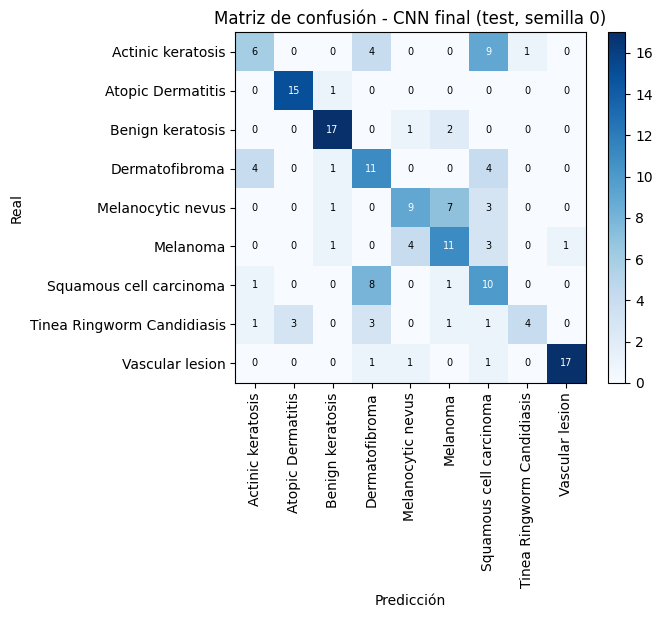

In [17]:
# ---- EVALUACIÓN EN TEST: se ejecuta una sola vez ----
final_rows, final_models, final_preds = [], {}, {}
for name, cfg in [("CNN final", FINAL_CFG), ("MLP 64px", {**BASE, "model": "mlp", "size": 64})]:
    accs, f1s, times = [], [], []
    for s in SEEDS_FINAL:
        m, h = fit(cfg, s); _, a, p = evaluate(m, idx_te, cfg["size"])
        accs.append(a); f1s.append(f1_score(labels[idx_te], p, average="macro")); times.append(sum(h["epoch_time"]))
        if s == SEEDS_FINAL[0]: final_models[name], final_preds[name] = m, p
    final_rows.append(dict(modelo=name, params=h["n_params"], test_acc=np.mean(accs), test_acc_std=np.std(accs), test_f1_macro=np.mean(f1s), f1_std=np.std(f1s), tiempo_entrenamiento_s=np.mean(times)))
final = pd.DataFrame(final_rows); display(final.round(4))
se = np.sqrt(final.loc[0, "test_acc"] * (1 - final.loc[0, "test_acc"]) / len(idx_te))
print(f"Error estándar binomial del test ({len(idx_te)} imágenes): ±{se:.3f} | azar: {1/NUM_CLASSES:.3f}")
p = final_preds["CNN final"]
print(classification_report(labels[idx_te], p, target_names=class_names, zero_division=0))
cm = confusion_matrix(labels[idx_te], p)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=90); plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title(f"Matriz de confusión - CNN final (test, semilla {SEEDS_FINAL[0]})"); plt.tight_layout(); plt.show()

## 9. ¿Qué aprende la red?
Se muestran (sobre imágenes de **validación**, no de test): los filtros de la primera convolución, los **mapas de activación** de la primera y la última capa convolucional para una imagen, y una galería de imágenes **mal clasificadas**.

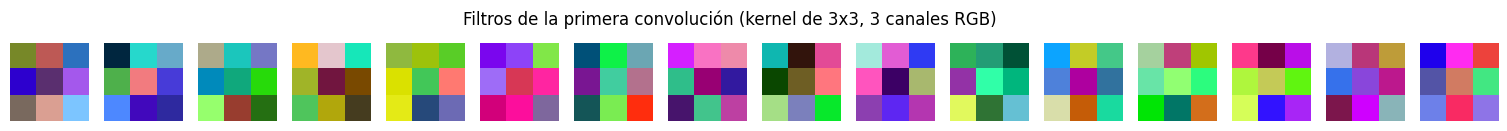

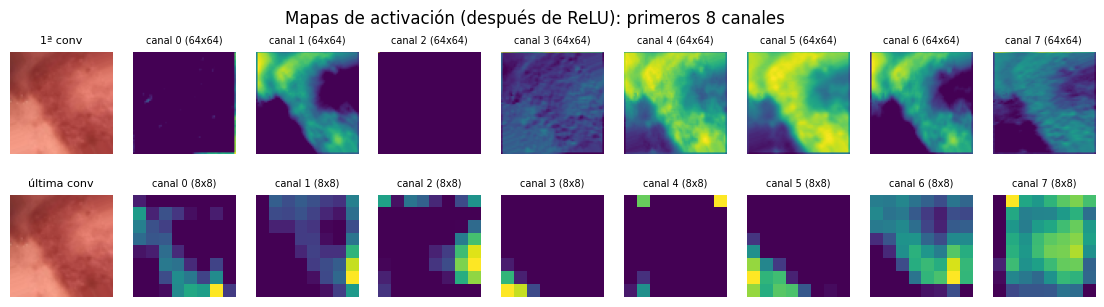

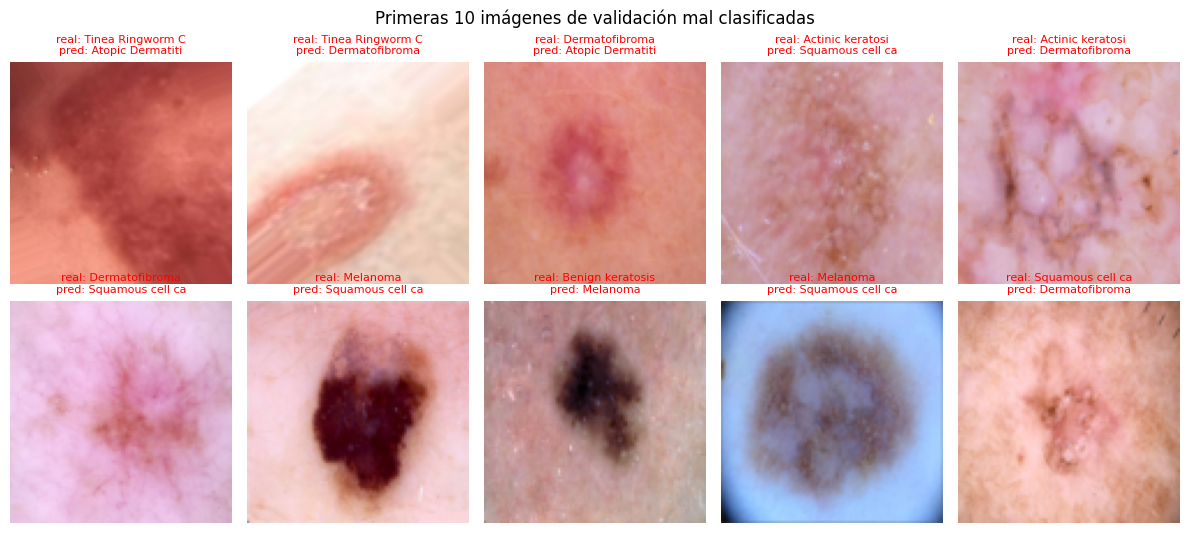

In [18]:
model = final_models["CNN final"].eval(); size = FINAL_CFG["size"]
W = model.features[0].weight.detach().cpu(); n = min(W.shape[0], 16)
fig, ax = plt.subplots(1, n, figsize=(1.2 * n, 1.5))
for i in range(n):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8); ax[i].imshow(w.permute(1, 2, 0), interpolation="nearest"); ax[i].axis("off")
fig.suptitle("Filtros de la primera convolución (kernel de %dx%d, 3 canales RGB)" % (W.shape[2], W.shape[3])); plt.show()

relu_pos = [i for i, l in enumerate(model.features) if isinstance(l, nn.ReLU)]
xi, yi = get_eval_batch(size, idx_va[:1])
with torch.no_grad(): a_first = model.features[:relu_pos[0] + 1](xi)[0].cpu(); a_last = model.features[:relu_pos[-1] + 1](xi)[0].cpu()
fig, ax = plt.subplots(2, 9, figsize=(14, 3.4))
for r_, (a, nm) in enumerate([(a_first, "1ª conv"), (a_last, "última conv")]):
    ax[r_, 0].imshow(X_U8[size][idx_va[0]].permute(1, 2, 0)); ax[r_, 0].set_title(nm, fontsize=8); ax[r_, 0].axis("off")
    for k in range(8): ax[r_, k + 1].imshow(a[k], cmap="viridis"); ax[r_, k + 1].axis("off"); ax[r_, k + 1].set_title(f"canal {k} ({a.shape[1]}x{a.shape[2]})", fontsize=7)
plt.suptitle("Mapas de activación (después de ReLU): primeros 8 canales"); plt.show()

_, _, pv = evaluate(model, idx_va, size)
bad = [i for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]; pbad = [p_ for i, p_ in zip(idx_va, pv) if p_ != labels[i]][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5.4))
for a, i, pr in zip(ax.flat, bad, pbad):
    a.imshow(X_U8[96][i].permute(1, 2, 0)); a.axis("off"); a.set_title(f"real: {class_names[labels[i]][:16]}\npred: {class_names[pr][:16]}", fontsize=8, color="red")
plt.suptitle("Primeras 10 imágenes de validación mal clasificadas"); plt.tight_layout(); plt.show()

### ✏️ TU ANÁLISIS 4 - Resultados finales e interpretación
1. **Consistencia val vs. test:** ¿el resultado de test es coherente con la validación? Tengan en cuenta el error estándar binomial del test y que elegimos el mejor entre varias configuraciones sobre validación (sesgo optimista).
2. **CNN vs. MLP en test:** ¿la diferencia supera el ruido entre semillas (± desvío) y el error estándar del test? ¿Se justifica el costo en parámetros/tiempo?
3. **Matriz de confusión y reporte por clase:** ¿qué clases se confunden más y por qué (similitud clínica/visual)? En este problema, ¿es igual de grave confundir cualquier par de clases? ¿Qué métrica (recall de melanoma, F1 macro, otra) les parece más relevante que el accuracy y por qué?
4. **Filtros, mapas de activación y errores:** ¿qué detectan las primeras capas y qué cambia en la última (tamaño espacial, nivel de abstracción)? ¿Qué patrones comunes tienen las imágenes mal clasificadas?
5. **Sesgos y limitaciones:** retomen el EDA (resoluciones y color por clase, duplicados). ¿Qué sesgos del dataset podrían inflar o distorsionar los números? Tamaño del dataset, una sola partición, pocas semillas, validación chica: ¿qué harían con más tiempo?

**1. Val contra test.** La config final (4 bloques, 64 px, sin augmentation) da val_acc 0,649 ± 0,010 al re-entrenar y **test 0,641 ± 0,053** (5 semillas): coherentes. El test tiene un error estándar binomial de ±0,037 (IC 95 % ≈ [0,57; 0,71]), así que cualquier valor entre ~0,60 y ~0,68 sería compatible. El sesgo optimista de elegir sobre val se ve en la secuencia 0,667 (sección 6, donde se eligió) → 0,649 (re-entrenado) → 0,641 (test): baja, pero poco, porque las diferencias entre variantes eran de por sí pequeñas. Cuidado: val_acc con la semilla 0 es 0,586 y test con la semilla 0 es 0,592; el valor de test de la semilla 0 es ~1 desvío por debajo de la media (0,641).

**2. CNN contra MLP en test.**

| | Params | test_acc | F1 macro | s de entrenamiento |
|---|---|---|---|---|
| CNN final | 361.113 | 0,641 ± 0,053 | 0,640 ± 0,059 | 2,0 |
| MLP 64px | 6.358.793 | 0,504 ± 0,053 | 0,487 ± 0,057 | 1,0 |

La diferencia es de +0,137 en accuracy y +0,153 en F1, unas 2,6 veces el desvío entre semillas y bastante más que el error de una diferencia pareada en 169 imágenes (< 0,05). Coincide con la val (+0,12 a +0,18). Con 17,6× menos parámetros y el doble de tiempo (irrelevante en términos absolutos), el costo se justifica. Pero la **semilla 0** (la que usamos para matriz y reporte) da CNN 0,592 y MLP 0,568; de las 169 imágenes, 72 las aciertan ambos, 28 solo la CNN, 24 solo la MLP y 45 ninguno. Con esa semilla los modelos son indistinguibles, así que las comparaciones por clase hay que leerlas con cautela.

**3. Matriz de confusión (CNN, semilla 0).** Mejores: Vascular lesion (F1 0,89), Atopic (0,88, recall 0,94) y Benign keratosis (0,83). Peores: Actinic keratosis (F1 0,38: 9 de 20 se predicen como SCC y 4 como Dermatofibroma), SCC (0,39; 8 de 20 se predicen como Dermatofibroma), Tinea (recall 0,31, precisión 0,80) y Dermatofibroma (0,47). Los pares son coherentes con la clínica: queratosis actínica y carcinoma escamoso son un continuo (la AK es precursora del SCC), ambas lesiones rosadas y rugosas; y nevus↔melanoma (7 nevus predichos melanoma, 4 melanomas predichos nevus) son las lesiones pigmentadas que también confunden a clínicos. A 64 px además se pierden detalles finos. Con 13–20 imágenes por clase, el error estándar del recall es ~0,11: diferencias por clase menores a ~0,2 son ruido.

**No todos los errores pesan igual.** Un melanoma clasificado como nevus (falso negativo) puede retrasar un diagnóstico potencialmente letal; un nevus clasificado como melanoma es una biopsia innecesaria; confundir AK con SCC suele implicar tratamiento en ambos casos. Aquí 9 de 20 melanomas no se detectaron como melanoma (4 como nevus). El accuracy es una métrica pobre para esto: preferiríamos el **recall (sensibilidad) del melanoma**, siempre acompañado de su precisión/especificidad, además del F1 macro (clases balanceadas, trata igual a todas). El recall de melanoma fue 0,55 (CNN) contra 0,35 (MLP), con ±0,11 de error estándar.

**4. Filtros, mapas y errores.** Los 16 filtros de 3×3 no son bordes orientados limpios: son sobre todo combinaciones de colores con pesos de signo opuesto entre canales (detectores de contraste de color o brillo) con poca estructura espacial, lo esperable con 506 imágenes y 3×3 px (además la figura los normaliza por filtro, así que no se ve la magnitud). En los mapas de la primera capa (64×64, un solo caso de val) los canales 1, 4, 5 y 6 siguen la zona oscura/rojiza de la imagen casi a resolución completa (color/luminosidad), los canales 3 y 7 muestran textura débil, y los canales 0 y 2 están casi apagados. En la última capa (8×8, campo receptivo de 38 px) los mapas son gruesos, dispersos y concentrados en regiones, un nivel más abstracto y espacialmente grosero, difícil de leer a ojo. Son 8 de 16 (primera) y 8 de 128 (última) canales, ilustrativos, no evidencia. En los errores de val (70 con la semilla 0, p.ej. AK 15 de 20, nevus 12, SCC 10, Tinea 9 de 13, y solo 2 en Vascular), las 10 imágenes de la galería muestran lesiones rosadas de bordes poco definidos (AK, SCC, Dermatofibroma, confundidas entre sí), lesiones pigmentadas (melanoma contra queratosis benigna) y fotos de Tinea que no parecen dermatoscopía (una con deformación visible y fondo claro, producto de `aug_`/redimensionado). Un melanoma con viñeta azul circular del dermatoscopio se clasificó como SCC.

**5. Sesgos y limitaciones.**
- **Fuente confundida con clase.** 4 clases son 100 % 600×450, Atopic es 100 % 294×222 y Tinea es web con tamaños y aspectos variados; el color medio también separa Atopic y Tinea. El modelo podría usar fuente/compresión/aspecto, lo que inflaría esas clases. Que el recall de Tinea sea 0,31 sugiere que no es un atajo perfecto, pero no lo descartamos.
- **Tinea con imágenes `aug_` (70 de 76, 58 nombres base).** Pueden existir copias de la misma foto entre train y test que ningún hash detectó; las 13 de test de Tinea son `aug_`. Faltaría agrupar por nombre base antes de dividir.
- **Duplicados.** Los 33 de train y val inflaban la val original en ~6 puntos por nuestra estimación; no hay forma de saber si hay duplicados por lesión o por paciente (no hay IDs).
- **Dataset y clases artificialmente balanceadas.** 844 imágenes, ~100 por clase (en la práctica el melanoma es mucho menos del 11 %), así que precisión y accuracy no se transfieren a la clínica. Además todo se achica a 64 px y a cuadrado.
- **Estadística.** Una sola partición (semilla 42), 169 imágenes en val y test (±0,037), 3 y 5 semillas que solo varían la inicialización, no la partición, ~14 decisiones sobre la misma val, y un no determinismo medido de ~0,03 entre repeticiones de la misma config (probablemente por la GPU).
- **Con más tiempo:** validación cruzada estratificada con grupos (nombre base/hash), `torch.use_deterministic_algorithms`, bootstrap para intervalos de confianza, transfer learning con un modelo preentrenado a 224 px, augmentation online, función de pérdida pesada hacia el recall de melanoma, preservar el aspecto en vez de aplastar a cuadrado, y evaluación en un dataset externo.

## Declaración de uso de IA
Completen (obligatorio): ¿usaron herramientas de IA? ¿Cuáles, para qué parte (código, redacción del análisis, ideas) y qué modificaron o verificaron por su cuenta? Si no usaron, aclaren que no.

> Se utilizó ChatGPT para verificar la redacción y encontrar errores de typo (especialmente porque los notebooks no tienen autocorrectores), y para detectar errores en los números citados de los outputs para justificar las respuestas de las secciones de análisis.

> Se utilizó Claude (modelo Sonnet 5.5) para adaptar el notebook para correr en Google Colab con la GPU T4 y para guardar automáticamente resultados relevantes (figuras y outputs textuales).